# Experiment 2: Logistic Regression on Titanic Dataset

**Aim:** To apply logistic regression on the Titanic dataset and predict passenger survival based on various features.

**Dataset:** Titanic dataset (`datasets/titanic.csv`, downloaded from
https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv).

In [1]:
# Step 1: Import required libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import os
os.makedirs("output", exist_ok=True)   # all plots are saved in this folder

In [2]:
# Step 2: Load dataset
data = pd.read_csv("datasets/titanic.csv")
print("Dataset shape:", data.shape)
print(data.head())

Dataset shape: (891, 12)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8

In [3]:
# Step 3: Data preprocessing
data = data[['Survived', 'Pclass', 'Sex', 'Age', 'Fare']].copy()
data.dropna(inplace=True)
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})  # Encode categorical variable
print("Shape after dropping missing values:", data.shape)
print(data.head())

Shape after dropping missing values: (714, 5)
   Survived  Pclass  Sex   Age     Fare
0         0       3    0  22.0   7.2500
1         1       1    1  38.0  71.2833
2         1       3    1  26.0   7.9250
3         1       1    1  35.0  53.1000
4         0       3    0  35.0   8.0500


In [4]:
# Step 4: Feature and target selection
X = data[['Pclass', 'Sex', 'Age', 'Fare']]
y = data['Survived']

# Step 5: Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 571
Testing samples : 143


In [5]:
# Step 6: Train Logistic Regression model
model = LogisticRegression()
model.fit(X_train, y_train)

print("Coefficients:", dict(zip(X.columns, model.coef_[0].round(4))))
print("Intercept   :", model.intercept_[0].round(4))

Coefficients: {'Pclass': -1.2407, 'Sex': 2.5305, 'Age': -0.0425, 'Fare': 0.0002}
Intercept   : 2.6117


In [6]:
# Step 7: Make predictions and evaluate
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.7552447552447552


Confusion Matrix:
[[68 19]
 [16 40]]


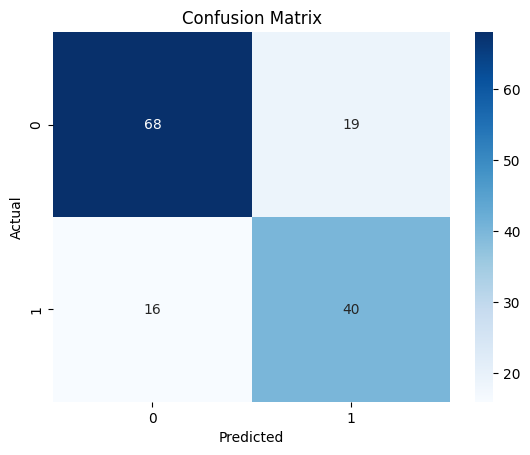

In [7]:
# Step 8: Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.savefig("output/Exp2_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion
Logistic Regression successfully predicted survival outcomes on the Titanic dataset. The model demonstrated how categorical and numerical features can be used to build a predictive classifier.